In [ ]:
!pip -q install datasets

from datasets import load_dataset

# Load the sentiment dataset
dataset = load_dataset("cardiffnlp/tweet_eval", "sentiment")

# Check available dataset splits
print("Dataset loaded successfully!")
print(dataset)

# Display one example from the training set
print("\nFirst training example:")
print(dataset["train"][0])


README.md:   0%|          | 0.00/23.9k [00:00<?, ?B/s]

sentiment/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.78MB            

sentiment/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sentiment/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  901kB            

sentiment/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sentiment/validation-00000-of-00001.parq(…): reconstructing file:   0%|          |  0.00B /  167kB            

sentiment/validation-00000-of-00001.parq(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/45615 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/12284 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Dataset loaded successfully!
DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 45615
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 12284
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})

First training example:
{'text': '"QT @user In the original draft of the 7th book, Remus Lupin survived the Battle of Hogwarts. #HappyBirthdayRemusLupin"', 'label': 2}


In [ ]:

# Check the size of each dataset split
print("Training examples:", len(dataset["train"]))
print("Validation examples:", len(dataset["validation"]))
print("Testing examples:", len(dataset["test"]))

# Check the sentiment labels
print("\nAvailable sentiment labels:")
print(dataset["train"].features["label"])


Training examples: 45615
Validation examples: 2000
Testing examples: 12284

Available sentiment labels:
ClassLabel(names=['negative', 'neutral', 'positive'])


In [ ]:

from collections import Counter

# Count sentiment labels in the training dataset
label_counts = Counter(dataset["train"]["label"])

# Get the actual label names
label_names = dataset["train"].features["label"].names

print("Sentiment Class Distribution in Training Data:\n")

for label_id, count in sorted(label_counts.items()):
    print(f"{label_names[label_id].capitalize()}: {count}")


Sentiment Class Distribution in Training Data:

Negative: 7093
Neutral: 20673
Positive: 17849


In [ ]:

!pip -q install nltk

import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Download the required English language resources
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

# Prepare stopwords and lemmatizer
stop_words = set(stopwords.words("english"))

# Preserve negation words because they affect sentiment
stop_words = stop_words - {"no", "nor", "not"}

lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    # Convert text to lowercase
    text = text.lower()

    # Remove URLs and user mentions
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"@\w+", " ", text)

    # Keep letters and spaces
    text = re.sub(r"[^a-z\s]", " ", text)

    # Tokenize, remove stopwords, and lemmatize
    words = text.split()
    words = [
        lemmatizer.lemmatize(word)
        for word in words
        if word not in stop_words
    ]

    return " ".join(words)

# Test preprocessing on one example
sample_text = dataset["train"][0]["text"]

print("Original text:")
print(sample_text)

print("\nPreprocessed text:")
print(preprocess_text(sample_text))


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Original text:
"QT @user In the original draft of the 7th book, Remus Lupin survived the Battle of Hogwarts. #HappyBirthdayRemusLupin"

Preprocessed text:
qt original draft th book remus lupin survived battle hogwarts happybirthdayremuslupin


In [ ]:

# Apply preprocessing to all three dataset splits

train_texts = [
    preprocess_text(text)
    for text in dataset["train"]["text"]
]

validation_texts = [
    preprocess_text(text)
    for text in dataset["validation"]["text"]
]

test_texts = [
    preprocess_text(text)
    for text in dataset["test"]["text"]
]

# Extract the corresponding sentiment labels
train_labels = dataset["train"]["label"]
validation_labels = dataset["validation"]["label"]
test_labels = dataset["test"]["label"]

print("Preprocessing completed successfully!")
print("Training texts:", len(train_texts))
print("Validation texts:", len(validation_texts))
print("Testing texts:", len(test_texts))

print("\nExample of processed text:")
print(train_texts[0])


Preprocessing completed successfully!
Training texts: 45615
Validation texts: 2000
Testing texts: 12284

Example of processed text:
qt original draft th book remus lupin survived battle hogwarts happybirthdayremuslupin


In [ ]:

from sklearn.feature_extraction.text import TfidfVectorizer

# Convert text into numerical TF-IDF features
tfidf_vectorizer = TfidfVectorizer(
    max_features=30000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

# Fit only on training data to prevent data leakage
X_train = tfidf_vectorizer.fit_transform(train_texts)

# Transform validation and test data using the same vocabulary
X_validation = tfidf_vectorizer.transform(validation_texts)
X_test = tfidf_vectorizer.transform(test_texts)

print("TF-IDF vectorization completed successfully!")
print("Training feature shape:", X_train.shape)
print("Validation feature shape:", X_validation.shape)
print("Testing feature shape:", X_test.shape)


TF-IDF vectorization completed successfully!
Training feature shape: (45615, 30000)
Validation feature shape: (2000, 30000)
Testing feature shape: (12284, 30000)


In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Initialize the model
sentiment_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

# Train the model on training data
print("Training the sentiment classification model...")

sentiment_model.fit(X_train, train_labels)

print("\nModel training completed successfully!")

# Evaluate on the validation set
validation_predictions = sentiment_model.predict(X_validation)

validation_accuracy = accuracy_score(
    validation_labels,
    validation_predictions
)

print(f"\nValidation Accuracy: {validation_accuracy:.4f}")

print("\nValidation Classification Report:")
print(
    classification_report(
        validation_labels,
        validation_predictions,
        labels=[0, 1, 2],
        target_names=["Negative", "Neutral", "Positive"],
        zero_division=0
    )
)


Training the sentiment classification model...

Model training completed successfully!

Validation Accuracy: 0.6585

Validation Classification Report:
              precision    recall  f1-score   support

    Negative       0.46      0.67      0.55       312
     Neutral       0.70      0.61      0.65       869
    Positive       0.73      0.70      0.72       819

    accuracy                           0.66      2000
   macro avg       0.63      0.66      0.64      2000
weighted avg       0.68      0.66      0.66      2000



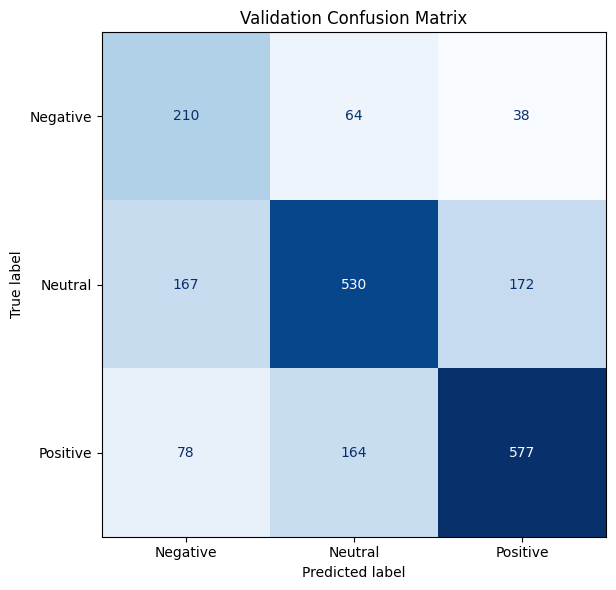

Confusion matrix values:
[[210  64  38]
 [167 530 172]
 [ 78 164 577]]


In [ ]:

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Create the confusion matrix
class_names = ["Negative", "Neutral", "Positive"]

cm = confusion_matrix(
    validation_labels,
    validation_predictions,
    labels=[0, 1, 2]
)

# Display the matrix
display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(7, 6))
display_matrix.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Validation Confusion Matrix")
plt.tight_layout()
plt.show()

print("Confusion matrix values:")
print(cm)


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score
)

# Calculate validation metrics
val_accuracy = accuracy_score(
    validation_labels, validation_predictions
)

val_macro_precision = precision_score(
    validation_labels, validation_predictions,
    average="macro", zero_division=0
)

val_macro_recall = recall_score(
    validation_labels, validation_predictions,
    average="macro", zero_division=0
)

val_macro_f1 = f1_score(
    validation_labels, validation_predictions,
    average="macro", zero_division=0
)

val_weighted_f1 = f1_score(
    validation_labels, validation_predictions,
    average="weighted", zero_division=0
)

print("VALIDATION PERFORMANCE")
print("-" * 35)
print(f"Accuracy:          {val_accuracy:.4f}")
print(f"Macro Precision:   {val_macro_precision:.4f}")
print(f"Macro Recall:      {val_macro_recall:.4f}")
print(f"Macro F1-score:    {val_macro_f1:.4f}")
print(f"Weighted F1-score: {val_weighted_f1:.4f}")


VALIDATION PERFORMANCE
-----------------------------------
Accuracy:          0.6585
Macro Precision:   0.6313
Macro Recall:      0.6625
Macro F1-score:    0.6392
Weighted F1-score: 0.6628


FINAL TEST PERFORMANCE
----------------------------------------
Test Accuracy:          0.5805
Test Macro F1-score:    0.5782
Test Weighted F1-score: 0.5784

Detailed Test Classification Report:
              precision    recall  f1-score   support

    Negative       0.53      0.71      0.61      3972
     Neutral       0.65      0.50      0.57      5937
    Positive       0.55      0.57      0.56      2375

    accuracy                           0.58     12284
   macro avg       0.58      0.59      0.58     12284
weighted avg       0.59      0.58      0.58     12284



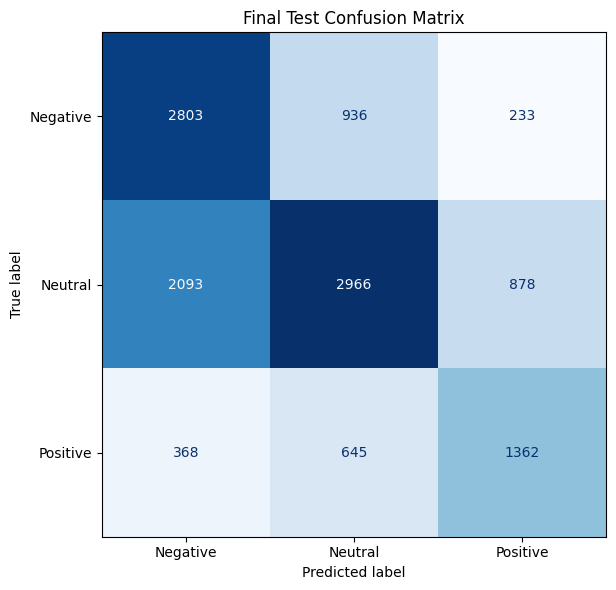

In [ ]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)
import matplotlib.pyplot as plt

# Predict sentiments for the unseen test dataset
test_predictions = sentiment_model.predict(X_test)

# Calculate final test metrics
test_accuracy = accuracy_score(
    test_labels, test_predictions
)

test_macro_f1 = f1_score(
    test_labels, test_predictions,
    average="macro", zero_division=0
)

test_weighted_f1 = f1_score(
    test_labels, test_predictions,
    average="weighted", zero_division=0
)

print("FINAL TEST PERFORMANCE")
print("-" * 40)
print(f"Test Accuracy:          {test_accuracy:.4f}")
print(f"Test Macro F1-score:    {test_macro_f1:.4f}")
print(f"Test Weighted F1-score: {test_weighted_f1:.4f}")

print("\nDetailed Test Classification Report:")
print(
    classification_report(
        test_labels,
        test_predictions,
        labels=[0, 1, 2],
        target_names=["Negative", "Neutral", "Positive"],
        zero_division=0
    )
)

# Plot the test confusion matrix
cm_test = confusion_matrix(
    test_labels, test_predictions,
    labels=[0, 1, 2]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_test,
    display_labels=["Negative", "Neutral", "Positive"]
)

fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Final Test Confusion Matrix")
plt.tight_layout()
plt.show()


In [ ]:

# Test the model on new example sentences

sample_sentences = [
    "I absolutely love this product, it is amazing!",
    "This is the worst experience I have ever had.",
    "The meeting will start at 3 PM today.",
    "I am not happy with the service.",
    "The food was okay, nothing special."
]

# Preprocess the sentences
processed_sentences = [
    preprocess_text(sentence)
    for sentence in sample_sentences
]

# Convert sentences using the existing TF-IDF vectorizer
sample_features = tfidf_vectorizer.transform(
    processed_sentences
)

# Predict sentiment labels
sample_predictions = sentiment_model.predict(
    sample_features
)

label_names = ["Negative", "Neutral", "Positive"]

print("SAMPLE SENTIMENT PREDICTIONS")
print("-" * 45)

for sentence, prediction in zip(
    sample_sentences, sample_predictions
):
    print(f"\nText: {sentence}")
    print(f"Predicted sentiment: {label_names[prediction]}")


SAMPLE SENTIMENT PREDICTIONS
---------------------------------------------

Text: I absolutely love this product, it is amazing!
Predicted sentiment: Positive

Text: This is the worst experience I have ever had.
Predicted sentiment: Negative

Text: The meeting will start at 3 PM today.
Predicted sentiment: Neutral

Text: I am not happy with the service.
Predicted sentiment: Negative

Text: The food was okay, nothing special.
Predicted sentiment: Positive


In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

# Compare candidate models using validation data only
candidates = [
    ("Logistic Regression C=0.5",
     LogisticRegression(
         C=0.5, max_iter=1000,
         class_weight="balanced", random_state=42
     )),
    ("Logistic Regression C=1.0",
     LogisticRegression(
         C=1.0, max_iter=1000,
         class_weight="balanced", random_state=42
     )),
    ("Logistic Regression C=2.0",
     LogisticRegression(
         C=2.0, max_iter=1000,
         class_weight="balanced", random_state=42
     )),
    ("Linear SVM C=0.5",
     LinearSVC(C=0.5, class_weight="balanced", random_state=42)),
    ("Linear SVM C=1.0",
     LinearSVC(C=1.0, class_weight="balanced", random_state=42)),
    ("Linear SVM C=2.0",
     LinearSVC(C=2.0, class_weight="balanced", random_state=42))
]

results = []
trained_models = {}

for name, model in candidates:
    print(f"Training and evaluating: {name}")

    model.fit(X_train, train_labels)
    predictions = model.predict(X_validation)

    accuracy = accuracy_score(
        validation_labels, predictions
    )
    macro_f1 = f1_score(
        validation_labels, predictions,
        average="macro", zero_division=0
    )
    weighted_f1 = f1_score(
        validation_labels, predictions,
        average="weighted", zero_division=0
    )

    results.append({
        "Model": name,
        "Validation Accuracy": round(accuracy, 4),
        "Macro F1": round(macro_f1, 4),
        "Weighted F1": round(weighted_f1, 4)
    })

    trained_models[name] = model

comparison_df = pd.DataFrame(results)
comparison_df = comparison_df.sort_values(
    by="Macro F1", ascending=False
).reset_index(drop=True)

print("\nVALIDATION MODEL COMPARISON")
display(comparison_df)


Training and evaluating: Logistic Regression C=0.5
Training and evaluating: Logistic Regression C=1.0
Training and evaluating: Logistic Regression C=2.0
Training and evaluating: Linear SVM C=0.5
Training and evaluating: Linear SVM C=1.0
Training and evaluating: Linear SVM C=2.0

VALIDATION MODEL COMPARISON


,Model,Validation Accuracy,Macro F1,Weighted F1
0,Logistic Regression C=2.0,0.6660,0.6456,0.6694
1,Linear SVM C=0.5,0.6670,0.6418,0.6685
2,Logistic Regression C=1.0,0.6585,0.6392,0.6628
3,Logistic Regression C=0.5,0.6525,0.6341,0.6574
4,Linear SVM C=1.0,0.6550,0.6270,0.6566
5,Linear SVM C=2.0,0.6460,0.6194,0.6471


Selected model: Logistic Regression C=2.0

FINAL TEST RESULTS
----------------------------------------
Test Accuracy: 0.5751
Test Macro F1: 0.5731
Test Weighted F1: 0.5735

Detailed Classification Report:
              precision    recall  f1-score   support

    Negative       0.54      0.68      0.60      3972
     Neutral       0.64      0.50      0.56      5937
    Positive       0.53      0.59      0.56      2375

    accuracy                           0.58     12284
   macro avg       0.57      0.59      0.57     12284
weighted avg       0.59      0.58      0.57     12284



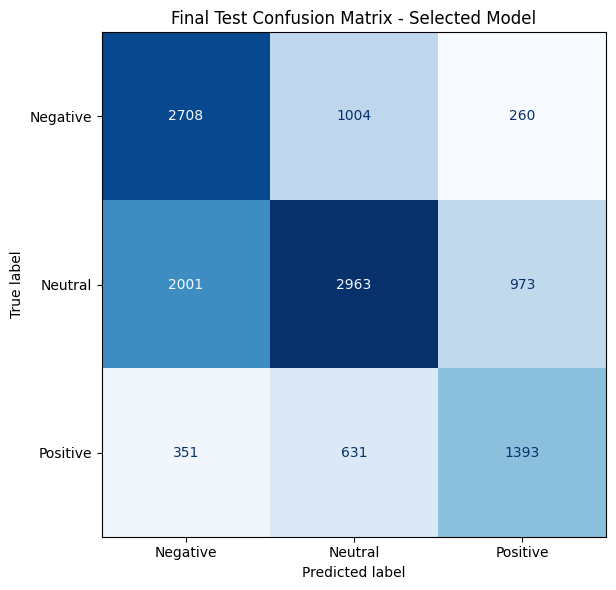

In [ ]:

# Select the best model based on validation Macro F1
best_model_name = comparison_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Selected model:", best_model_name)

# Evaluate on the untouched test dataset
final_test_predictions = best_model.predict(X_test)

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)
import matplotlib.pyplot as plt

print("\nFINAL TEST RESULTS")
print("-" * 40)

print(
    "Test Accuracy:",
    round(accuracy_score(test_labels, final_test_predictions), 4)
)

print(
    "Test Macro F1:",
    round(
        f1_score(
            test_labels, final_test_predictions,
            average="macro", zero_division=0
        ), 4
    )
)

print(
    "Test Weighted F1:",
    round(
        f1_score(
            test_labels, final_test_predictions,
            average="weighted", zero_division=0
        ), 4
    )
)

print("\nDetailed Classification Report:")
print(
    classification_report(
        test_labels,
        final_test_predictions,
        labels=[0, 1, 2],
        target_names=["Negative", "Neutral", "Positive"],
        zero_division=0
    )
)

# Final test confusion matrix
final_cm = confusion_matrix(
    test_labels, final_test_predictions,
    labels=[0, 1, 2]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=final_cm,
    display_labels=["Negative", "Neutral", "Positive"]
)

fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
plt.title("Final Test Confusion Matrix - Selected Model")
plt.tight_layout()
plt.show()
